# Weight clipping versus gradient penalty: a PyTorch tutorial

Antonio Peña Peña, Geer Wang Liu and Zhenhua Ye Xiang

This notebook explains the implementation behind *Weight Clipping versus Gradient Penalty in Wasserstein GAN Training*. We compare two unconditional generators trained on CIFAR-10. WGAN constrains the critic by clipping its weights; WGAN-GP adds a penalty on input gradients.

[Project repository](https://github.com/zhenhuaaaa/Proyecto_IAG) · [Experimental notebook](https://github.com/zhenhuaaaa/Proyecto_IAG/blob/main/main.ipynb) · [Project report](../report/IA_GEN_PROYECTO_FINAL.pdf)

By the end, you will be able to prepare image tensors, follow the generator and critic architectures, execute both update rules, load trained generators and interpret the saved evaluation results. Familiarity with Python, tensors and backpropagation is assumed.

The tutorial follows the sequence of the [PyTorch CIFAR-10 tutorial](https://docs.pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html): data, model, objective, training and evaluation. Here the task is image generation, so class labels are not training targets.

## How to run this notebook

From the repository root, install `requirements.txt` in a Python 3.11 virtual environment and run `python -m jupyter lab docs/tutorial.ipynb`. Then select **Restart Kernel and Run All Cells**. The default path needs no internet or CUDA once dependencies and repository checkpoints are present. It executes a small update demonstration, generates samples from the final checkpoints, reads the saved CSV and plots training histories. It never writes to the experimental checkpoints or metric files.

The full 200,000-iteration experiments are in `main.ipynb`; do not use its **Run All** command for a quick demonstration. Instructions for repeating them are in the documentation's reproduction guide.

The outputs below have two origins. Model checks, update demonstrations and final-checkpoint inference are executed for this tutorial. The full experiment's CSV and the figures explicitly marked *historical* are read from the supplied project. The tutorial does not claim to repeat the original training or recompute FID, KID, IS, Recall and Coverage.

In [1]:
from pathlib import Path
import json
import platform
import importlib.metadata as metadata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import CIFAR10
from torchvision.utils import make_grid

# Support Jupyter launched from either the repository root or docs/.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "main.ipynb").is_file()
            and (p / "evaluation_metrics/metrics_all_checkpoints.csv").is_file())
DEVICE = torch.device("cpu")
Z_DIM = MODEL_DIM = 128
SEED = 42
RUN_CIFAR_DOWNLOAD = False
RUN_CHECKPOINT_INFERENCE = True

torch.manual_seed(SEED)
np.random.seed(SEED)
torch.set_num_threads(min(4, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False})
print("Python:", platform.python_version(), "| device:", DEVICE)
for package in ("torch", "torchvision", "numpy", "pandas", "matplotlib"):
    print(f"{package}: {metadata.version(package)}")

Python: 3.11.7 | device: cpu
torch: 2.2.2
torchvision: 0.17.2
numpy: 1.26.4
pandas: 2.1.4
matplotlib: 3.11.0


## 1. Prepare the data

CIFAR-10 contains 50,000 training and 10,000 test images of shape 3 × 32 × 32. The project uses the training split to update the networks and the test split as the real reference for evaluation. It ignores class labels when training the generators.

`ToTensor()` converts an RGB image to a floating-point tensor in [0, 1]. `Normalize(0.5, 0.5)` applies $x'=2x-1$, matching the generator's `tanh` output in [-1, 1]. Before display or PNG export, invert this transformation with $(x'+1)/2$.

The following cell checks that conversion on a small RGB image without downloading a dataset. A shape of `(3, 32, 32)` and a round-trip error of zero are expected.

In [2]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
pixels = np.arange(32 * 32 * 3, dtype=np.uint8).reshape(32, 32, 3)
normalized = transform(Image.fromarray(pixels))
restored = (((normalized + 1) / 2).clamp(0, 1).permute(1, 2, 0)
            .numpy() * 255).round().astype(np.uint8)
assert normalized.shape == (3, 32, 32)
assert torch.isfinite(normalized).all()
assert np.array_equal(restored, pixels)
print("Tensor shape:", tuple(normalized.shape))
print("Range:", float(normalized.min()), float(normalized.max()))
print("Maximum RGB round-trip error:", np.abs(restored.astype(int) - pixels).max())

Tensor shape: (3, 32, 32)
Range: -1.0 1.0
Maximum RGB round-trip error: 0


### Optional: load the full training split

Set `RUN_CIFAR_DOWNLOAD = True` in the configuration cell to execute the project's data-loading path. The first run downloads roughly 170 MB and needs additional space for extracted files. `shuffle=True` permutes the dataset and `drop_last=True` keeps batches at 64 images. The later short update demonstration deliberately uses synthetic inputs so the default notebook can run offline.

In [3]:
if RUN_CIFAR_DOWNLOAD:
    training_data = CIFAR10(root=str(ROOT / "data"), train=True,
                            download=True, transform=transform)
    training_loader = DataLoader(training_data, batch_size=64,
                                 shuffle=True, drop_last=True, num_workers=0)
    real_batch, labels = next(iter(training_loader))
    assert real_batch.shape == (64, 3, 32, 32)
    print("Training images:", len(training_data))
    print("Classes:", training_data.classes)
    print("Batch:", tuple(real_batch.shape))
else:
    print("Full CIFAR-10 loading is disabled; the default tutorial needs no download.")

Full CIFAR-10 loading is disabled; the default tutorial needs no download.


The following preview comes from the saved output of the original notebook's data section. It shows training examples and their labels; it is not generated by the synthetic check above.

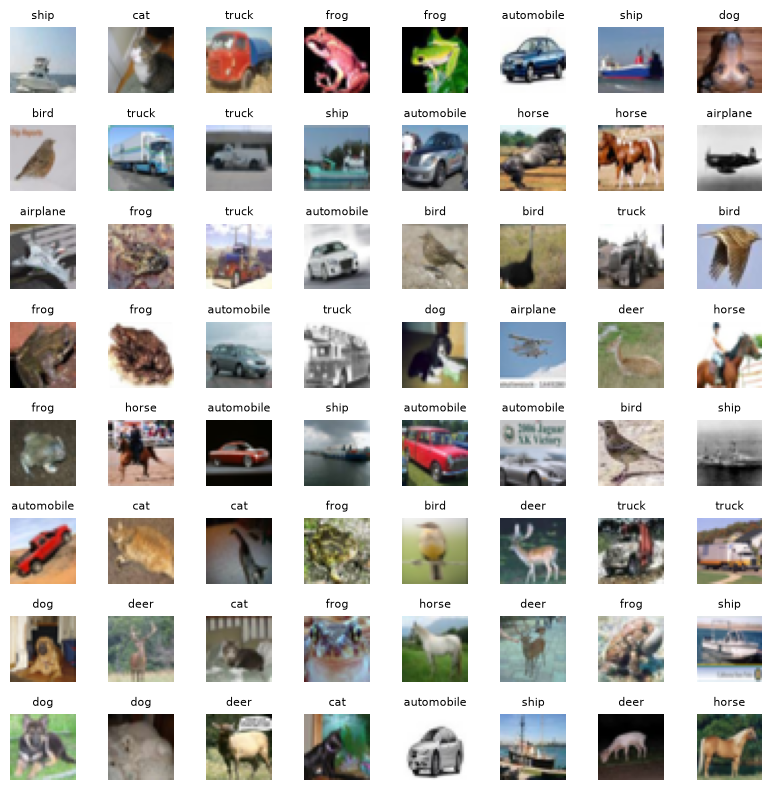

## 2. Define the generator and critics

The next three class definitions are copied from `main.ipynb` without changing their computations. Their cell metadata records the original zero-based cell index. They are included here so the implementation can be read and executed in one place.

For the experiment, `dim=128` and `latent_dim=128`. The generator maps Gaussian noise to an 8,192-value vector, reshapes it to 512 × 4 × 4, then upsamples to 32 × 32. Transposed convolutions use a 5 × 5 kernel, stride 2, padding 2 and output padding 1.

| Generator operation | Output per image |
| --- | --- |
| Linear, BatchNorm, ReLU | 8,192 |
| Reshape | 512 × 4 × 4 |
| Transposed convolution, BatchNorm, ReLU | 256 × 8 × 8 |
| Transposed convolution, BatchNorm, ReLU | 128 × 16 × 16 |
| Transposed convolution, tanh | 3 × 32 × 32 |

### Generator

In [4]:
class Generator(nn.Module):
    def __init__(self, latent_dim=Z_DIM, dim=MODEL_DIM):
        super().__init__()

        self.latent_dim = latent_dim
        self.dim = dim

        self.linear =  nn.Linear(latent_dim, 4 * 4 * 4 * dim)

        self.bn1 = nn.BatchNorm1d(4 * 4 * 4 * dim)

        self.deconv1 = nn.ConvTranspose2d(4 * dim, 2 * dim, kernel_size=5, stride=2, padding=2, output_padding=1)

        self.bn2 = nn.BatchNorm2d(2 * dim)

        self.deconv2 = nn.ConvTranspose2d(2 * dim, dim, kernel_size=5, stride=2, padding=2, output_padding=1)

        self.bn3 = nn.BatchNorm2d(dim)

        self.deconv3 = nn.ConvTranspose2d(dim, 3, kernel_size=5, stride=2, padding=2, output_padding=1)

        self.relu = nn.ReLU()

        self.tanh = nn.Tanh()

    def forward(self, z):
        # Linear transformation
        x = self.linear(z)

        # Batch normalization + ReLU activation
        x = self.bn1(x)
        x = self.relu(x)

        # Reshape into a 4x4 feature map
        x = x.view(-1, 4 * self.dim, 4, 4)

        # 4x4 -> 8x8
        x = self.deconv1(x)
        x = self.bn2(x)
        x = self.relu(x)

        # 8x8 -> 16x16
        x = self.deconv2(x)
        x = self.bn3(x)
        x = self.relu(x)

        # 16x16 -> 32x32
        x = self.deconv3(x)

        # Output activation
        x = self.tanh(x)

        return x

### WGAN critic

The critic reduces spatial resolution from 32 to 16, 8 and 4 with 5 × 5 convolutions. A linear layer produces one real-valued score per image. There is no sigmoid: this score is not a probability. The WGAN implementation includes BatchNorm after the second and third convolutions.

In [5]:
class Critic(nn.Module):
    def __init__(self, dim=MODEL_DIM):
        super().__init__()

        self.dim = dim

        self.conv1 = nn.Conv2d(3, dim, kernel_size=5, stride=2, padding=2)

        self.leaky_relu = nn.LeakyReLU(0.2)

        self.conv2 = nn.Conv2d(dim, 2 * dim, kernel_size=5, stride=2, padding=2)

        self.bn2 = nn.BatchNorm2d(2 * dim) #NOTE: Comment this line to ignore batch normalization

        self.conv3 = nn.Conv2d(2 * dim, 4 * dim, kernel_size=5, stride=2, padding=2)

        self.bn3 = nn.BatchNorm2d(4 * dim) #NOTE: Comment this line to ignore batch normalization

        self.linear = nn.Linear(4 * 4 * 4 * dim, 1)

    def forward(self, x):
        # 32x32 -> 16x16
        x = self.conv1(x)
        x = self.leaky_relu(x)

        # 16x16 -> 8x8
        x = self.conv2(x)
        x = self.bn2(x) #NOTE: Comment this line to ignore batch normalization
        x = self.leaky_relu(x)

        # 8x8 -> 4x4
        x = self.conv3(x)
        x = self.bn3(x) #NOTE: Comment this line to ignore batch normalization
        x = self.leaky_relu(x)

        # Flatten
        x = x.view(-1, 4 * 4 * 4 * self.dim)

        # Linear transformation
        x = self.linear(x)

        return x

### WGAN-GP critic

`CriticGP` has the same convolution sizes and no BatchNorm. BatchNorm in training mode couples examples in the batch, whereas this penalty is defined through a gradient for each individual input.

In [6]:
class CriticGP(nn.Module):
    def __init__(self, dim=128):
        super().__init__()

        self.dim = dim

        # 32x32 -> 16x16
        self.conv1 = nn.Conv2d(3, dim, kernel_size=5, stride=2, padding=2)
        # 16x16 -> 8x8
        self.conv2 = nn.Conv2d(dim, 2 * dim, kernel_size=5, stride=2, padding=2)
        # 8x8 -> 4x4
        self.conv3 = nn.Conv2d(2 * dim, 4 * dim, kernel_size=5, stride=2, padding=2)
        # 4*dim channels x 4 x 4 -> scalar critic score
        self.linear = nn.Linear(4 * 4 * 4 * dim, 1)

        self.leaky_relu = nn.LeakyReLU(0.2)

    def forward(self, x):
        # 32x32 -> 16x16
        x = self.conv1(x)
        x = self.leaky_relu(x)

        # 16x16 -> 8x8
        x = self.conv2(x)
        x = self.leaky_relu(x)

        # 8x8 -> 4x4
        x = self.conv3(x)
        x = self.leaky_relu(x)

        # Flatten
        x = x.view(-1, 4 * 4 * 4 * self.dim)

        # Linear transformation
        x = self.linear(x)

        return x

# Batch Normalization is omitted because it couples samples within a batch.
# WGAN-GP computes a per-sample gradient penalty, so this dependency would
# make the penalty difficult to interpret.

### Check the interface

We use the full experiment width here. An input `(4, 128)` must produce images `(4, 3, 32, 32)` and either critic must return `(4, 1)`. Randomly initialized networks only check these interfaces; they do not yet generate learned CIFAR-10 images.

In [7]:
torch.manual_seed(SEED)
shape_generator = Generator().to(DEVICE).eval()
shape_critic = Critic().to(DEVICE).eval()
shape_critic_gp = CriticGP().to(DEVICE).eval()
with torch.no_grad():
    noise = torch.randn(4, Z_DIM, device=DEVICE)
    fake = shape_generator(noise)
    scores = shape_critic(fake)
    scores_gp = shape_critic_gp(fake)
assert fake.shape == (4, 3, 32, 32)
assert scores.shape == scores_gp.shape == (4, 1)
assert fake.min() >= -1 and fake.max() <= 1
print("Noise:", tuple(noise.shape), "Images:", tuple(fake.shape))
print("Critic outputs:", tuple(scores.shape), tuple(scores_gp.shape))
for name, model in [("Generator", shape_generator), ("Critic", shape_critic),
                    ("CriticGP", shape_critic_gp)]:
    print(f"{name}: {sum(p.numel() for p in model.parameters()):,} trainable parameters")
del shape_generator, shape_critic, shape_critic_gp

Noise: (4, 128) Images: (4, 3, 32, 32)
Critic outputs: (4, 1) (4, 1)
Generator: 5,179,907 trainable parameters
Critic: 4,116,225 trainable parameters
CriticGP: 4,114,689 trainable parameters


## 3. Train WGAN with weight clipping

With generated images $\tilde{x}=G(z)$, the critic minimizes

$$L_D = \mathbb{E}[D(\tilde{x})] - \mathbb{E}[D(x)].$$

The generator minimizes $L_G=-\mathbb{E}[D(G(z))]$. A lower critic loss means a larger separation between real and generated scores at that step, not necessarily better generated images. Absolute losses from differently constrained critics are not directly comparable quality scores.

During the critic update, `fake_images.detach()` blocks gradients into the generator. After the optimizer step, every trainable critic parameter is clipped to [-0.01, 0.01]. This includes BatchNorm's learnable scale and bias. The implementation uses RMSprop at `5e-5` for both networks. Weight clipping constrains parameters but does not establish an exact global 1-Lipschitz bound.

The following functions are the actual update rules from the experiment.

In [8]:
def train_critic(generator, critic, real_images, optimizer_D, z_dim, device):
    batch_size = real_images.size(0)

    # Generate fake images
    z = torch.randn(batch_size, z_dim, device=device)
    fake_images = generator(z)

    # Compute Wasserstein loss
    real_scores = critic(real_images)
    fake_scores = critic(fake_images.detach())
    critic_loss = torch.mean(fake_scores) - torch.mean(real_scores)

    # Update critic parameters
    optimizer_D.zero_grad()
    critic_loss.backward()
    optimizer_D.step()

    # Weight clipping
    for p in critic.parameters():
        p.data.clamp_(-0.01, 0.01)

    return critic_loss.item()

def train_generator(generator, critic, optimizer_G, batch_size, z_dim, device):
    z = torch.randn(batch_size, z_dim, device=device)

    fake_images = generator(z)

    # Compute generator loss
    fake_scores = critic(fake_images)
    generator_loss = -torch.mean(fake_scores)

    # Update generator parameters
    optimizer_G.zero_grad()
    generator_loss.backward()
    optimizer_G.step()

    return generator_loss.item()

## 4. Train WGAN-GP with an input-gradient penalty

Choose a random coefficient independently for each pair of images and interpolate between them:

$$\hat{x}=x+\alpha(\tilde{x}-x),\qquad \alpha\sim U(0,1).$$

The penalty is

$$GP=\mathbb{E}_{\hat{x}}\left[(\|\nabla_{\hat{x}}D(\hat{x})\|_2-1)^2\right],$$

and the total critic loss is $L_D^{GP}=L_D+\lambda GP$, with $\lambda=10$. It penalizes norms both below and above one at sampled interpolation points. It does not guarantee a norm of one everywhere.

`interpolate_samples` broadcasts one coefficient over all channels and pixels of an image.

In [9]:
def interpolate_samples(real_images, fake_images):
    """
    Creates random interpolations between real and generated images.

    Args:
        real_images: Tensor of real images with shape (B, C, H, W).
        fake_images: Tensor of generated images with shape (B, C, H, W).

    Returns:
        interpolated_images: Tensor with shape (B, C, H, W).
    """

    batch_size = real_images.size(0)

    alpha = torch.rand(batch_size, 1, 1, 1, device=real_images.device)
    differences = fake_images - real_images
    interpolated_images = real_images + (alpha * differences)
    return interpolated_images

`gradient_penalty` differentiates the critic's score with respect to its input, flattens each image's gradient, and computes its L2 norm. `create_graph=True` retains the graph needed to differentiate this penalty with respect to the critic parameters during the subsequent backward pass.

In [10]:
def gradient_penalty(critic, interpolated_images):
    """
    Computes the gradient penalty for WGAN-GP.

    Args:
        critic: WGAN-GP critic network.
        interpolated_images: Tensor of interpolated images
                             with shape (B, C, H, W).

    Returns:
        gradient_penalty: Scalar gradient penalty.
    """

    interpolated_images = interpolated_images.detach().requires_grad_(True)

    interpolated_scores = critic(interpolated_images)

    gradients = torch.autograd.grad(
        outputs=interpolated_scores,
        inputs=interpolated_images,
        grad_outputs=torch.ones_like(interpolated_scores),
        create_graph=True,
        retain_graph=True
    )[0]

    # (B, C, H, W) -> (B, C*H*W)
    gradients = gradients.reshape(gradients.size(0), -1)

    # Compute the L2 norm of the gradient for each image
    slopes = gradients.norm(2, dim=1)

    # Gradient penalty
    gradient_penalty = ((slopes - 1.0) ** 2).mean()

    return gradient_penalty

`wgan_gp_critic_loss` returns three tensors: total loss, the unregularized Wasserstein component and the unweighted penalty. Keeping them separate makes the training plots interpretable.

In [11]:
def wgan_gp_critic_loss(
    critic,
    real_images,
    fake_images,
    lambda_gp=10.0
):

    # Critic scores
    real_scores = critic(real_images)
    fake_scores = critic(fake_images.detach())

    # Same Wasserstein component as in WGAN
    wasserstein_loss = (fake_scores.mean() - real_scores.mean())

    # Interpolated samples
    interpolated_images = interpolate_samples(real_images, fake_images.detach())

    # Gradient penalty
    gp = gradient_penalty(critic, interpolated_images)

    # Total WGAN-GP critic loss
    critic_loss = ( wasserstein_loss + lambda_gp * gp)

    return ( critic_loss, wasserstein_loss, gp)

The critic update generates images under `torch.no_grad()` and performs no weight clipping. The generator has the same loss as in WGAN. For WGAN-GP, both optimizers are Adam with learning rate `1e-4` and betas `(0.5, 0.9)`.

In [12]:
# ==============================================================
# 4.4 TRAIN CRITIC
# ==============================================================

def train_critic_gp(
    generator,
    critic,
    real_images,
    optimizer_D,
    z_dim,
    device,
    lambda_gp=10.0
):

    batch_size_current = real_images.size(0)

    # Random latent vectors
    z = torch.randn( batch_size_current, z_dim, device=device)

    # Generate fake images
    # Generator is not updated during critic training
    with torch.no_grad():
        fake_images = generator(z)

    # WGAN-GP loss
    critic_loss, wasserstein_loss, gp = (
        wgan_gp_critic_loss(  critic=critic, real_images=real_images, fake_images=fake_images, lambda_gp=lambda_gp ))

    # Update critic
    optimizer_D.zero_grad()
    critic_loss.backward()
    optimizer_D.step()

    # No weight clipping in WGAN-GP
    return ( critic_loss.item(), wasserstein_loss.item(), gp.item() )

In [13]:
# ==============================================================
# 4.5 TRAIN GENERATOR
# ==============================================================

def train_generator_gp(
    generator,
    critic,
    optimizer_G,
    batch_size,
    z_dim,
    device
):

    # Random latent vectors
    z = torch.randn( batch_size,  z_dim,  device=device)

    # Generate fake images
    fake_images = generator(z)

    # Critic scores
    fake_scores = critic(fake_images)

    # Generator Wasserstein loss
    generator_loss = (-fake_scores.mean())

    # Update generator
    optimizer_G.zero_grad()

    generator_loss.backward()

    optimizer_G.step()

    return generator_loss.item()

### Check the penalty against a known gradient

For a critic that sums an image's pixels and divides by the square root of the number of pixels, the gradient norm is exactly one. Its penalty should therefore be zero. Multiplying that critic by two gives a penalty of one. This check tests the formula independently of trained weights.

In [14]:
class KnownGradientCritic(nn.Module):
    def __init__(self, scale):
        super().__init__()
        self.scale = nn.Parameter(torch.tensor(float(scale), dtype=torch.float64))

    def forward(self, x):
        flat = x.flatten(1)
        return self.scale * flat.sum(1, keepdim=True) / np.sqrt(flat.shape[1])

probe = torch.randn(4, 3, 32, 32, dtype=torch.float64)
unit_critic = KnownGradientCritic(1)
double_critic = KnownGradientCritic(2)
unit_penalty = gradient_penalty(unit_critic, probe)
double_penalty = gradient_penalty(double_critic, probe)
assert torch.allclose(unit_penalty, torch.tensor(0.0, dtype=torch.float64), atol=1e-10)
assert torch.allclose(double_penalty, torch.tensor(1.0, dtype=torch.float64), atol=1e-10)
double_penalty.backward()
assert torch.isfinite(double_critic.scale.grad)
print(f"Norm 1 penalty: {unit_penalty.item():.6f}")
print(f"Norm 2 penalty: {double_penalty.item():.6f}")
print(f"Gradient through the penalty: {double_critic.scale.grad.item():.6f}")

Norm 1 penalty: 0.000000
Norm 2 penalty: 1.000000
Gradient through the penalty: 2.000000


## 5. Execute a small training demonstration

This cell performs five critic updates and one generator update for each method. It uses four synthetic images and `dim=8` to keep CPU execution short. The update functions and latent dimension are unchanged. The printed losses are only checks that the computation runs; they are not CIFAR-10 results and must not be used in the report's comparison.

Fresh model instances ensure this demonstration does not alter the supplied trained networks. The assertions check finite losses, a generator parameter change and the WGAN clipping bound.

In [15]:
torch.manual_seed(SEED)
synthetic_images = torch.rand(4, 3, 32, 32, device=DEVICE) * 2 - 1
smoke_rows = []
for method in ("WGAN", "WGAN-GP"):
    demo_g = Generator(latent_dim=Z_DIM, dim=8).to(DEVICE).train()
    demo_d = (Critic(dim=8) if method == "WGAN" else CriticGP(dim=8)).to(DEVICE).train()
    before = demo_g.linear.weight.detach().clone()
    if method == "WGAN":
        opt_g = torch.optim.RMSprop(demo_g.parameters(), lr=5e-5)
        opt_d = torch.optim.RMSprop(demo_d.parameters(), lr=5e-5)
        for _ in range(5):
            d_loss = train_critic(demo_g, demo_d, synthetic_images, opt_d, Z_DIM, DEVICE)
        assert max(p.detach().abs().max().item() for p in demo_d.parameters()) <= 0.010001
        g_loss = train_generator(demo_g, demo_d, opt_g, 4, Z_DIM, DEVICE)
        penalty = None
    else:
        opt_g = torch.optim.Adam(demo_g.parameters(), lr=1e-4, betas=(0.5, 0.9))
        opt_d = torch.optim.Adam(demo_d.parameters(), lr=1e-4, betas=(0.5, 0.9))
        for _ in range(5):
            d_loss, wasserstein, penalty = train_critic_gp(
                demo_g, demo_d, synthetic_images, opt_d, Z_DIM, DEVICE, lambda_gp=10.0)
        g_loss = train_generator_gp(demo_g, demo_d, opt_g, 4, Z_DIM, DEVICE)
        assert penalty >= 0 and np.isfinite(penalty)
    assert np.isfinite([d_loss, g_loss]).all()
    assert not torch.equal(before, demo_g.linear.weight)
    smoke_rows.append({"Method": method, "Critic loss": d_loss,
                       "Generator loss": g_loss, "Unweighted GP": penalty})
display(pd.DataFrame(smoke_rows).round(6))
del demo_g, demo_d, opt_g, opt_d

,Method,Critic loss,Generator loss,Unweighted GP
0,WGAN,-0.000419,-0.006939,NaN
1,WGAN-GP,9.328266,-0.020279,0.932693


### Scale up to the experiment

The original runs use the following settings. An “iteration” is one generator update after five critic updates, not a pass over the dataset.

| Setting | WGAN | WGAN-GP |
| --- | --- | --- |
| Training images | CIFAR-10 train, 50,000 | Same |
| Batch size / base width / latent size | 64 / 128 / 128 | Same |
| Generator updates | 200,000 | 200,000 |
| Critic updates per generator update | 5 | 5 |
| Optimizer | RMSprop | Adam |
| Learning rate | 0.00005 | 0.0001 |
| Adam betas | Not applicable | 0.5, 0.9 |
| Critic normalization | BatchNorm | None |
| Constraint | Clip to ±0.01 | GP coefficient 10 |
| Milestone checkpoints | 1,000; 10,000; 100,000; 200,000 | Same |

To repeat the experiment, run the data and model sections of `main.ipynb`, configure a suitable device, and then run its training sections. The supplied recovery checkpoints resume completed runs, so use separate checkpoint directories for a new run. The reproduction guide lists the cells, output paths and checkpoint formats.

The original loops use `cycle(train_loader)`, which caches and repeats the first traversal's batches. They do not record the complete random-number-generator state. Consequently, restarting a run is not guaranteed to reproduce it bit for bit. The original environment is also not fully recorded; the installation file describes the environment verified for this tutorial.

## 6. Generate images from the trained checkpoints

The trained generator has the same architecture in both methods, but the checkpoint keys differ: WGAN stores weights under `generator`; WGAN-GP uses `generator_state_dict`. We load onto CPU, switch to `eval()` to use BatchNorm's running statistics, then generate images under `torch.no_grad()`.

The next cell generates 16 images per final checkpoint from exactly the same Gaussian noise. It reads the supplied weights and does not retrain. `.pt` files are stored with Git LFS; after cloning, use `git lfs pull` if a checkpoint is only a small text pointer. If you only want to inspect the saved results, set `RUN_CHECKPOINT_INFERENCE = False`.

WGAN: loaded wgan_iter_200000.pth; saved iteration=199999


WGAN-GP: loaded wgan_gp_iter_200000.pt; saved iteration=200000


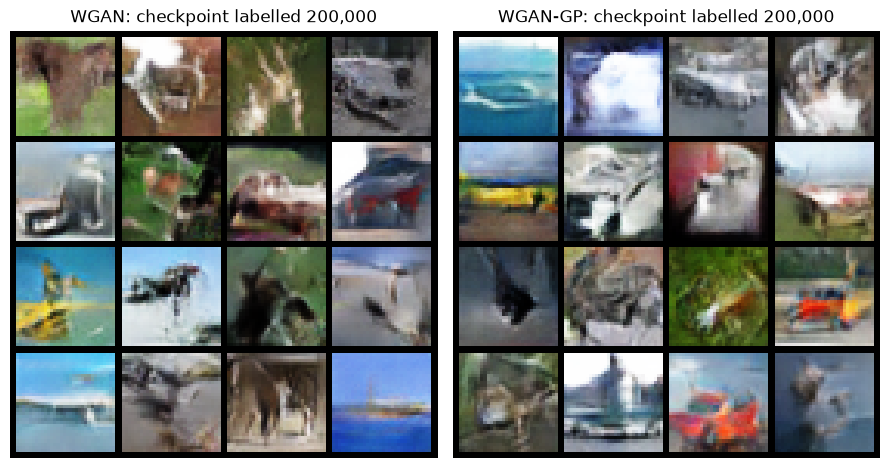

In [16]:
checkpoint_paths = {
    "WGAN": ROOT / "checkpoints/wgan_bn/wgan_iter_200000.pth",
    "WGAN-GP": ROOT / "checkpoints/wgan_gp/wgan_gp_iter_200000.pt",
}
histories = {}
if RUN_CHECKPOINT_INFERENCE:
    noise_rng = torch.Generator(device="cpu").manual_seed(SEED)
    shared_noise = torch.randn(16, Z_DIM, generator=noise_rng).to(DEVICE)
    fig, axes = plt.subplots(1, 2, figsize=(9, 5))
    for ax, (name, checkpoint_path) in zip(axes, checkpoint_paths.items()):
        if not checkpoint_path.is_file():
            raise FileNotFoundError(f"Missing {checkpoint_path.name}; retrieve repository checkpoints.")
        if checkpoint_path.stat().st_size < 1024:
            raise RuntimeError(f"{checkpoint_path.name} looks like a Git LFS pointer. Run git lfs pull.")
        checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
        key = "generator" if name == "WGAN" else "generator_state_dict"
        trained_g = Generator(latent_dim=Z_DIM, dim=MODEL_DIM).to(DEVICE)
        trained_g.load_state_dict(checkpoint[key], strict=True)
        trained_g.eval()
        with torch.no_grad():
            images = ((trained_g(shared_noise).cpu() + 1) / 2).clamp(0, 1)
        assert images.shape == (16, 3, 32, 32) and torch.isfinite(images).all()
        ax.imshow(make_grid(images, nrow=4, padding=2).permute(1, 2, 0).numpy())
        ax.set_title(f"{name}: checkpoint labelled 200,000")
        ax.axis("off")
        histories[name] = {k: checkpoint[k] for k in
                           ("iteration", "generator_losses", "critic_losses", "gradient_penalties")
                           if k in checkpoint}
        print(f"{name}: loaded {checkpoint_path.name}; saved iteration={checkpoint['iteration']}")
        del trained_g, checkpoint
    plt.tight_layout()
    plt.show()
else:
    print("Checkpoint inference is disabled. Historical figures and CSV remain available below.")

### Follow the earlier checkpoints

This historical figure is the saved comparison from `main.ipynb`, section 5.1. Rows correspond to 1,000, 10,000, 100,000 and 200,000 generator updates, in that order; columns are WGAN and WGAN-GP. The original comparison uses 64 shared latent vectors with seed 42. It illustrates earlier emergence of recognizable objects in the WGAN-GP run. A visual grid alone cannot establish the distribution's diversity or quantify mode collapse.

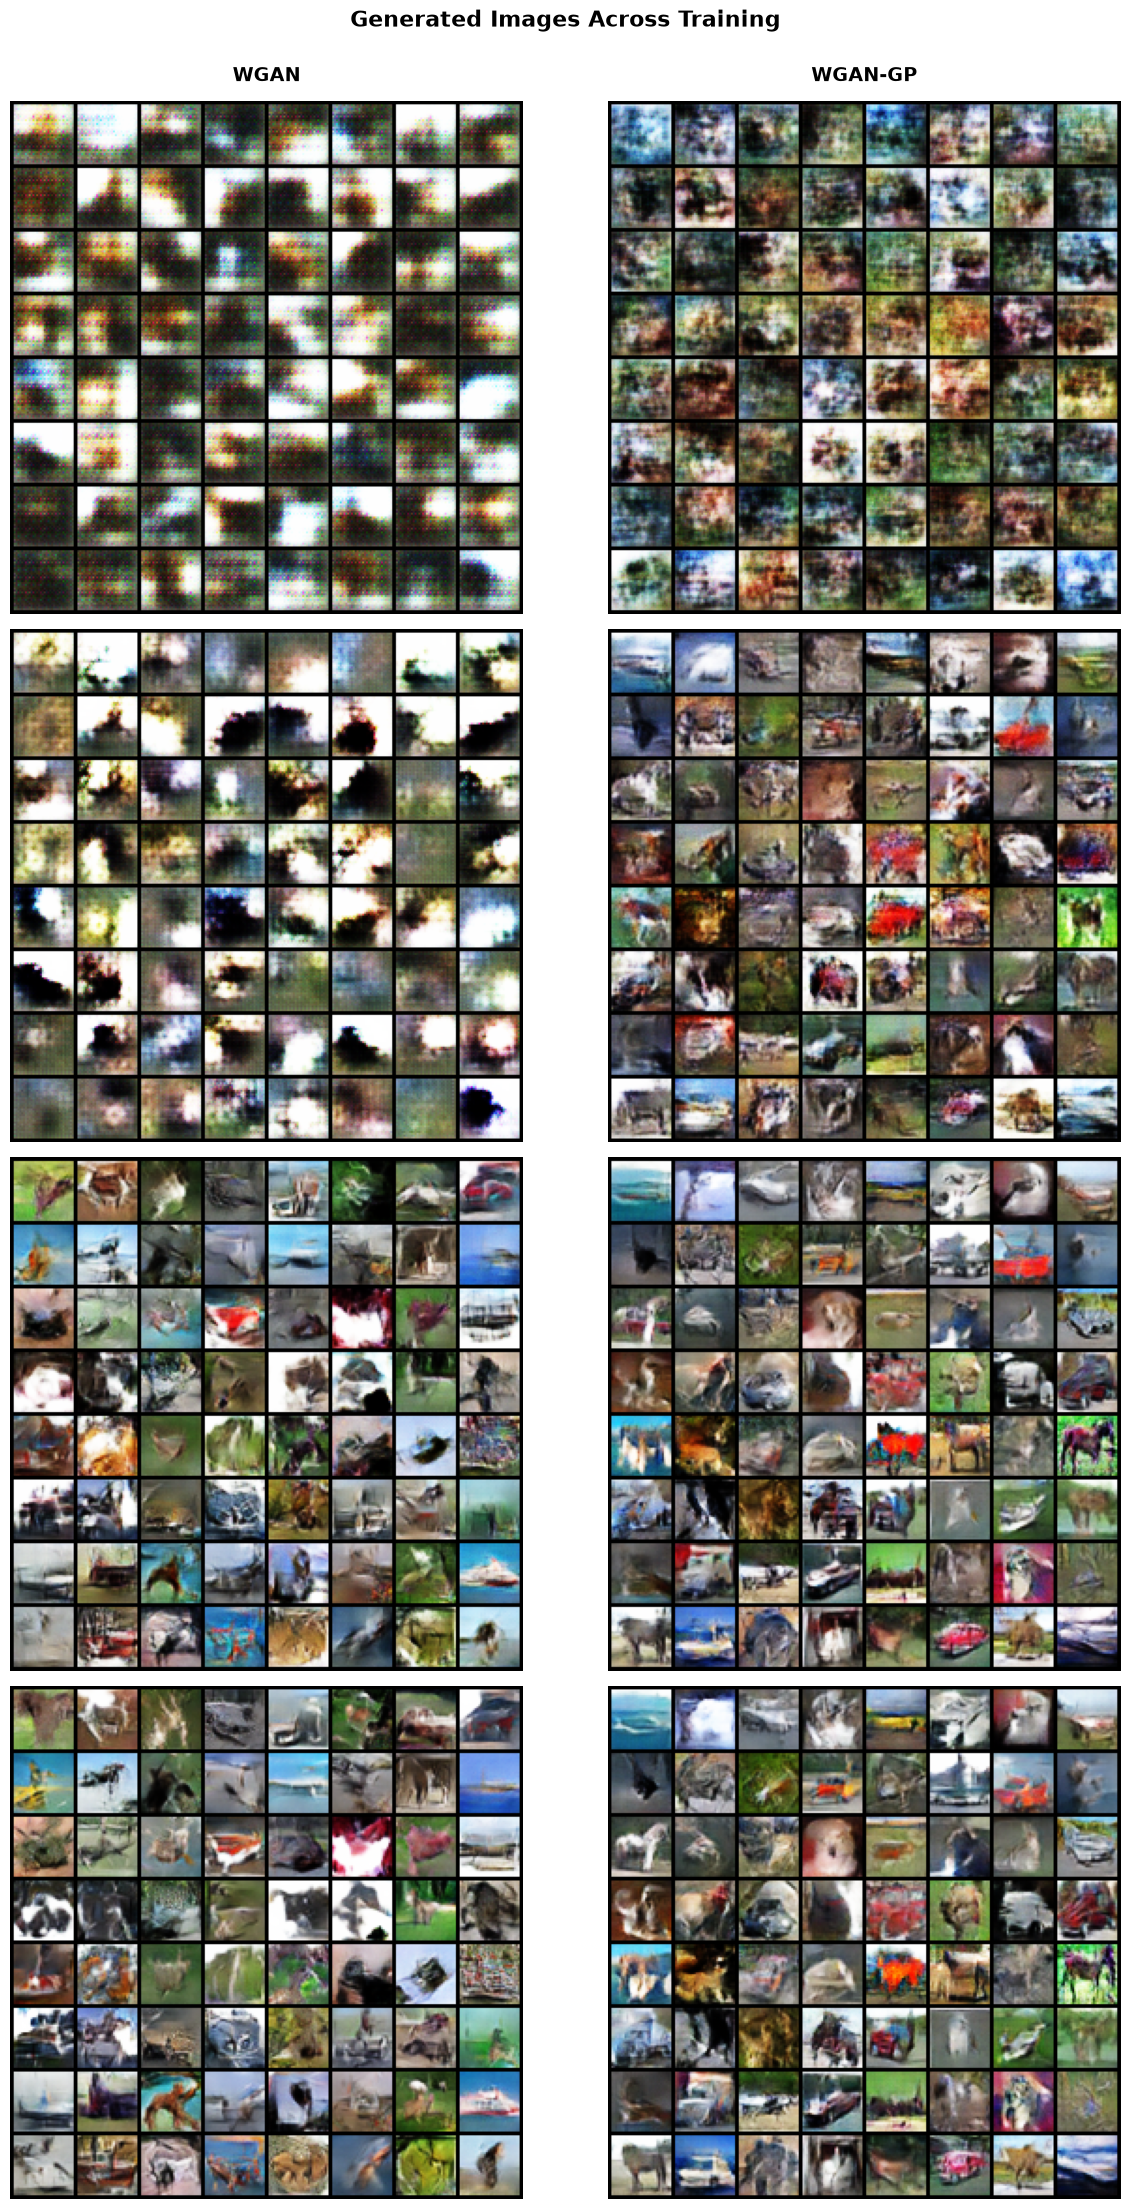

## 7. Inspect training losses and gradient behavior

The next plots are reconstructed from the final checkpoints. Their history lengths do not agree exactly with the iteration counters. WGAN contains 200,001 generator and 1,000,005 critic records, with `iteration=199999`. WGAN-GP contains 200,034 generator and 1,000,193 critic records, with `iteration=200000`. The files do not establish the cause or location of the extra records.

We therefore plot each history against its own recorded index, without aligning five critic entries to each generator entry. Moving averages use 200 generator records or 1,000 critic records. The checkpoint names identify the experimental milestones; they do not establish an exact correspondence between counter values and history lengths.

The total WGAN-GP critic loss includes its regularization term, whereas WGAN's does not. Compare changes within a curve rather than treating the two loss scales as competing quality scores.

,Model,Saved iteration,Generator records,Critic records
0,WGAN,199999,200001,1000005
1,WGAN-GP,200000,200034,1000193


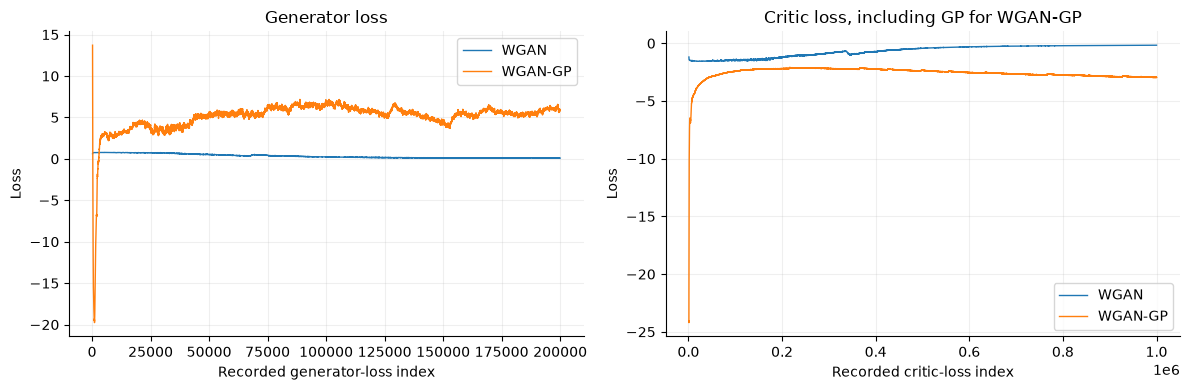

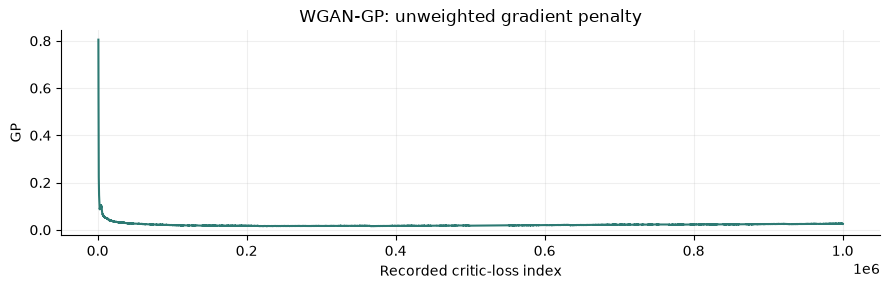

In [17]:
if histories:
    display(pd.DataFrame([
        {"Model": name, "Saved iteration": h["iteration"],
         "Generator records": len(h["generator_losses"]),
         "Critic records": len(h["critic_losses"])}
        for name, h in histories.items()
    ]))
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    plot_specs = [
        ("generator_losses", 200, "Generator loss", "Recorded generator-loss index"),
        ("critic_losses", 1000, "Critic loss, including GP for WGAN-GP", "Recorded critic-loss index"),
    ]
    for ax, (key, window, title, xlabel) in zip(axes, plot_specs):
        for name, history in histories.items():
            values = np.asarray(history[key], dtype=float)
            assert len(values) > 0 and np.isfinite(values).all()
            width = min(window, len(values))
            smoothed = np.convolve(values, np.ones(width) / width, mode="valid")
            ax.plot(np.arange(width, len(values) + 1), smoothed, label=name, linewidth=1)
        ax.set(title=title, xlabel=xlabel, ylabel="Loss")
        ax.grid(alpha=0.2)
        ax.legend()
    plt.tight_layout()
    plt.show()

    penalty = np.asarray(histories["WGAN-GP"]["gradient_penalties"], dtype=float)
    assert len(penalty) > 0 and np.isfinite(penalty).all()
    width = min(1000, len(penalty))
    smoothed = np.convolve(penalty, np.ones(width) / width, mode="valid")
    fig, ax = plt.subplots(figsize=(9, 3))
    ax.plot(np.arange(width, len(penalty) + 1), smoothed, color="#2d7a73")
    ax.set(title="WGAN-GP: unweighted gradient penalty",
           xlabel="Recorded critic-loss index", ylabel="GP")
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
else:
    print("Training histories are plotted when checkpoint inference is enabled.")

A small average penalty means input-gradient norms are close to one at sampled interpolation points on average. It does not establish a global Lipschitz property.

The following historical histograms use 1,000 real test images per checkpoint with the critic in evaluation mode. These are gradients **at real images**, not at the interpolations used to train WGAN-GP. `torch.autograd.grad` must stay enabled even though the critic is in `eval()` mode. Here `eval()` affects layer behavior; it does not disable automatic differentiation.

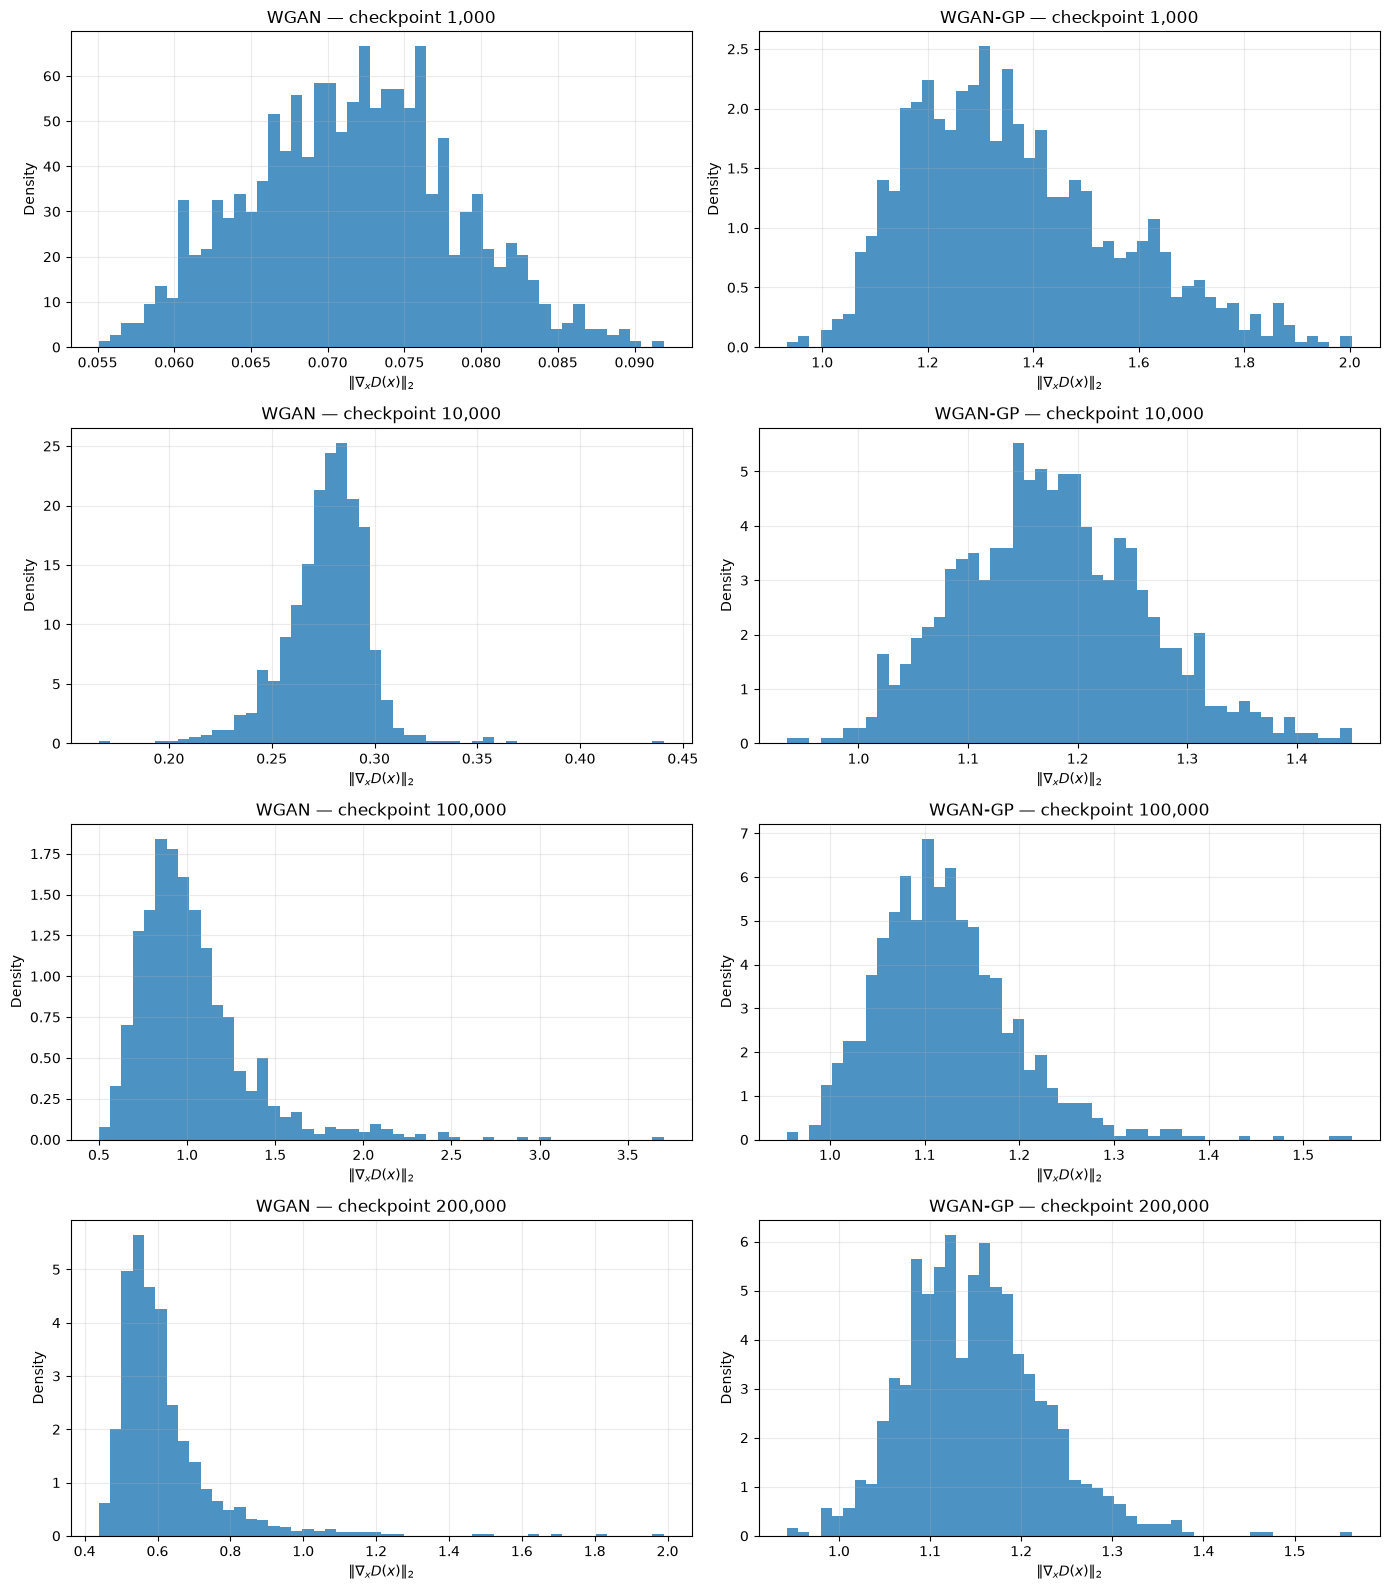

## 8. Read and compare the recorded evaluation metrics

We now load the project's CSV. These are the saved experimental measurements, not estimates from the synthetic demonstration. The evaluation code uses 10,000 generated images per checkpoint and the 10,000-image CIFAR-10 test split as reference, with latent-sampling seed 1234.

| Metric | Interpretation | Preferred direction |
| --- | --- | --- |
| FID | Distance between Gaussian summaries of real and generated Inception features | Lower |
| KID | Kernel discrepancy between real and generated feature samples | Lower |
| IS | Confidence and marginal diversity of generated-image classifier predictions | Higher |
| Recall | Fraction of real features covered by the generated feature manifold | Higher |
| Coverage | Fraction of real features with a generated neighbor within their real-data neighborhood radius | Higher |

FID, KID and IS use `torch-fidelity`. Recall and Coverage use `prdc` with `nearest_k=5`, on features from TorchVision Inception-v3 with ImageNet weights and its final classifier replaced by an identity. These are different feature-extraction pipelines. The KID standard deviation reflects five random subsets of size 1,000; it is not variation across independent training runs. Inception Score does not compare against real images and is not a complete measure of quality.

In [18]:
metrics = pd.read_csv(ROOT / "evaluation_metrics/metrics_all_checkpoints.csv")
assert len(metrics) == 8
assert not metrics.duplicated(["Model", "Iteration"]).any()
assert set(metrics["Iteration"]) == {1000, 10000, 100000, 200000}
assert set(metrics["Model"]) == {"WGAN", "WGAN-GP"}
metric_columns = {
    "FID (lower is better)": "FID (lower)",
    "KID mean (lower is better)": "KID (lower)",
    "IS mean (higher is better)": "IS (higher)",
    "Recall (higher is better)": "Recall (higher)",
    "Coverage (higher is better)": "Coverage (higher)",
}
assert np.isfinite(metrics[list(metric_columns)].to_numpy()).all()
display(metrics[["Model", "Iteration", *metric_columns]].rename(columns=metric_columns).round(6))

,Model,Iteration,FID (lower),KID (lower),IS (higher),Recall (higher),Coverage (higher)
0,WGAN,1000,304.056348,0.314283,1.720969,0.0000,0.0081
1,WGAN-GP,1000,201.785560,0.199682,2.081636,0.0022,0.0432
2,WGAN,10000,185.753780,0.175041,2.314343,0.0066,0.0389
3,WGAN-GP,10000,88.766539,0.071111,4.587406,0.1077,0.2672
4,WGAN,100000,59.479416,0.040897,5.473463,0.2436,0.3559
5,WGAN-GP,100000,40.620540,0.027173,6.335675,0.4413,0.5059
6,WGAN,200000,42.744192,0.026846,6.136335,0.4268,0.4549
7,WGAN-GP,200000,40.199831,0.026540,6.266605,0.4295,0.5176


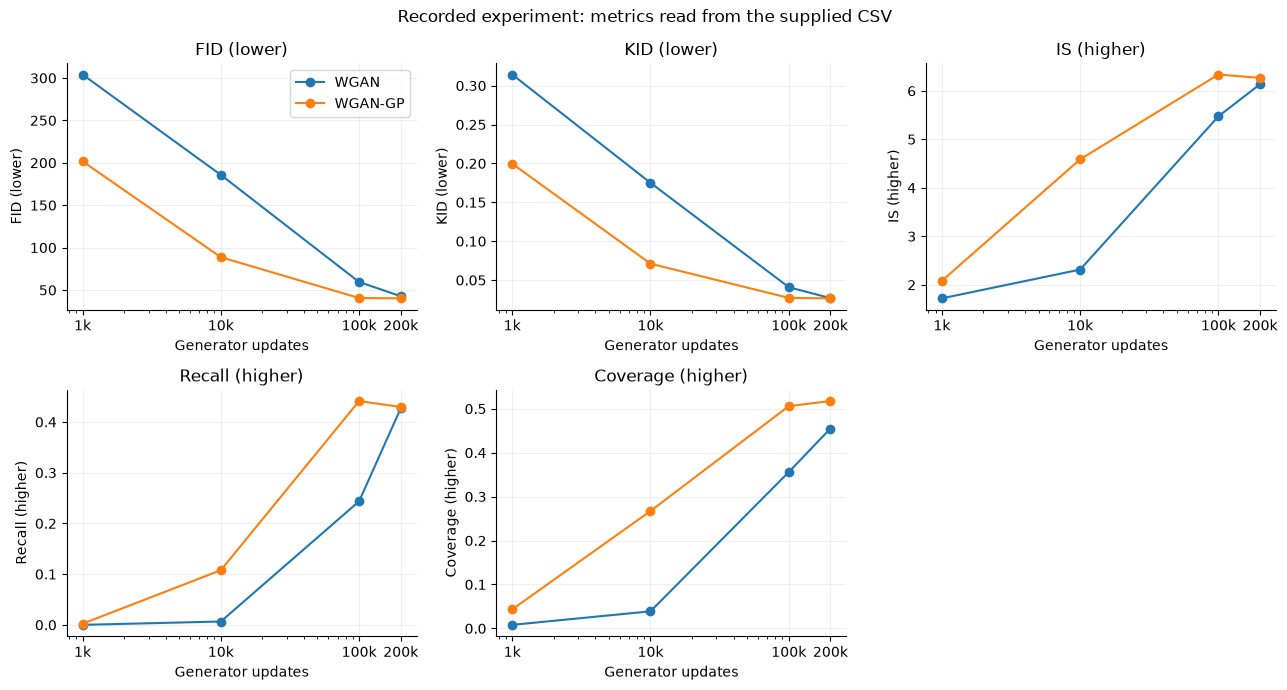

,FID (lower),KID (lower),IS (higher),Recall (higher),Coverage (higher)
Model,,,,,
WGAN,42.744192,0.026846,6.136335,0.4268,0.4549
WGAN-GP,40.199831,0.026540,6.266605,0.4295,0.5176


In [19]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, (column, label) in zip(axes.flat, metric_columns.items()):
    for name, group in metrics.groupby("Model", sort=False):
        group = group.sort_values("Iteration")
        ax.plot(group["Iteration"], group[column], marker="o", label=name)
    ax.set(xscale="log", xlabel="Generator updates", ylabel=label, title=label)
    ax.set_xticks([1000, 10000, 100000, 200000], ["1k", "10k", "100k", "200k"])
    ax.grid(alpha=0.2)
axes.flat[0].legend()
axes.flat[-1].axis("off")
fig.suptitle("Recorded experiment: metrics read from the supplied CSV")
plt.tight_layout()
plt.show()

final_metrics = metrics.loc[metrics["Iteration"] == 200000, ["Model", *metric_columns]]
display(final_metrics.rename(columns=metric_columns).set_index("Model").round(6))

At 10,000 updates, recorded FID is 185.75 for WGAN and 88.77 for WGAN-GP. At 200,000 updates it is 42.74 and 40.20, respectively. The final IS values are 6.14 and 6.27, and Coverage is 0.4549 and 0.5176. WGAN-GP has the better final value in all five recorded columns, but the final KID and Recall differences are small. Its IS and Recall are slightly higher at 100,000 than at 200,000 updates, so progress is not monotonic for every metric.

This is a comparison of two configurations, not an isolated test of the gradient penalty. The optimizer, learning rate and critic normalization also differ. A single training run per configuration cannot establish statistical significance or variability across seeds.

### Recompute metrics with the correct image range

Before exporting normalized real images to PNG, convert [-1, 1] back to [0, 1], clamp, multiply by 255 and round. The current documentation update fixes a missing inverse normalization in the real-image export of `main.ipynb`. Its earlier comment incorrectly described the input as [0, 1].

The historical CSV, notebook outputs and report are preserved. They were not regenerated after this correction, and the supplied files do not establish exactly which earlier preprocessing state produced them. This limits exact reproduction of the reported numbers. A new quantitative run should use the corrected conversion, separate output paths and a recorded environment. That run also requires Inception weight downloads, the full test split, the optional evaluation dependencies and substantially more computation and memory than this tutorial.

## 9. What the implementation demonstrates

You have executed the models' forward paths, both optimizer-update rules, an independent gradient-penalty check and inference with trained weights. The saved experiments show faster early improvement by the WGAN-GP configuration, with smaller differences at the final checkpoint.

Useful follow-up experiments would keep optimizer and normalization choices controlled, repeat training with several seeds, record elapsed time and evaluate gradients both at real images and at interpolations. Preserve the current artifacts as the record of this partial replication.

## Sources and project files

- Arjovsky, Chintala and Bottou. [Wasserstein GAN](https://arxiv.org/abs/1701.07875), 2017.
- Gulrajani et al. [Improved Training of Wasserstein GANs](https://arxiv.org/abs/1704.00028), 2017.
- [CIFAR-10 dataset](https://www.cs.toronto.edu/~kriz/cifar.html).
- Heusel et al. [GANs Trained by a Two Time-Scale Update Rule Converge to a Local Nash Equilibrium](https://arxiv.org/abs/1706.08500), 2017. FID.
- Bińkowski et al. [Demystifying MMD GANs](https://arxiv.org/abs/1801.01401), 2018. KID.
- Salimans et al. [Improved Techniques for Training GANs](https://arxiv.org/abs/1606.03498), 2016. Inception Score.
- Naeem et al. [Reliable Fidelity and Diversity Metrics for Generative Models](https://arxiv.org/abs/2002.09797), 2020, and the [PRDC implementation](https://github.com/clovaai/generative-evaluation-prdc).
- [torch-fidelity](https://torch-fidelity.readthedocs.io/) documents the FID/KID/IS implementation.
- The original implementation is in `main.ipynb`; the evaluated measurements are in `evaluation_metrics/metrics_all_checkpoints.csv`. `references/gan_cifar.py` and `references/gan_cifar_resnet.py` are TensorFlow reference scripts, not dependencies of this PyTorch tutorial.

Documentation preparation used OpenAI Codex for explanatory text, runnable examples and the Sphinx build. The recorded experiments and quantitative results come from the supplied project; no training results were invented for this documentation.